<a href="https://colab.research.google.com/github/rehanshaikh7862228-code/future-scope-of-data-science/blob/main/PDS_PBL-3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Name:** Rehan Shaikh  
**Enrollment No.:** 240090107202  
**Course:** B.E. Computer Engineering  
**Subject:** Python for Data Science  
**PBL Activity:** PBL 3  
**Project Title:** Future scope of data science  
**Dataset:** Data Science job salaries Dataset  

**Description:**  
In this step, the customer churn dataset is uploaded and loaded using Pandas. The first five records, dataset shape, and column names are displayed to understand the structure of the dataset.

In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

print("Libraries loaded successfully!")

Libraries loaded successfully!


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files

# Upload dataset
uploaded = files.upload()

# Get uploaded file name automatically
file_name = next(iter(uploaded))

# Load dataset
df = pd.read_csv(file_name)

# Display first 5 rows
print("First 5 rows of the dataset:")
display(df.head())

# Display shape
print("\nDataset Shape:", df.shape)

# Display column names
print("\nColumn Names:")
print(df.columns.tolist())

Saving ds_salaries.csv to ds_salaries.csv
First 5 rows of the dataset:


,Unnamed: 0,work_year,experience_level,employment_type,job_title,salary,salary_currency,salary_in_usd,employee_residence,remote_ratio,company_location,company_size
0,0,2020,MI,FT,Data Scientist,70000,EUR,79833,DE,0,DE,L
1,1,2020,SE,FT,Machine Learning Scientist,260000,USD,260000,JP,0,JP,S
2,2,2020,SE,FT,Big Data Engineer,85000,GBP,109024,GB,50,GB,M
3,3,2020,MI,FT,Product Data Analyst,20000,USD,20000,HN,0,HN,S
4,4,2020,SE,FT,Machine Learning Engineer,150000,USD,150000,US,50,US,L



Dataset Shape: (607, 12)

Column Names:
['Unnamed: 0', 'work_year', 'experience_level', 'employment_type', 'job_title', 'salary', 'salary_currency', 'salary_in_usd', 'employee_residence', 'remote_ratio', 'company_location', 'company_size']


## Step 2: Data Cleaning


In [ ]:
# Check for missing values
print("Missing Values:")
print(df.isnull().sum())

# Check for duplicate records
print("\nNumber of Duplicate Records:")
print(df.duplicated().sum())

Missing Values:
Unnamed: 0            0
work_year             0
experience_level      0
employment_type       0
job_title             0
salary                0
salary_currency       0
salary_in_usd         0
employee_residence    0
remote_ratio          0
company_location      0
company_size          0
dtype: int64

Number of Duplicate Records:
0


##Step 3: Data Preprocessing

In [ ]:
# ==========================================
# STEP 3: DATA PREPROCESSING
# ==========================================

# 1. Dataset information
print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())

# 2. Missing values check
print("\nMissing Values:")
print(df.isnull().sum())

# 3. Duplicate values check
print("\nNumber of Duplicate Rows:")
print(df.duplicated().sum())

# 4. Remove duplicate rows (if any)
df = df.drop_duplicates()

print("\nShape after removing duplicates:", df.shape)

# 5. Check data types
print("\nData Types:")
print(df.dtypes)

# 6. Create target variable
# Salary above median = High
# Salary at or below median = Standard

median_salary = df["salary_in_usd"].median()

df["market_value"] = np.where(
    df["salary_in_usd"] > median_salary,
    "High",
    "Standard"
)

print("\nMedian Salary:", median_salary)

# 7. Check target variable
print("\nMarket Value Distribution:")
print(df["market_value"].value_counts())

# 8. Display final preprocessed data
print("\nFirst 5 Rows:")
display(df.head())

Dataset Shape: (607, 12)

Column Names:
['Unnamed: 0', 'work_year', 'experience_level', 'employment_type', 'job_title', 'salary', 'salary_currency', 'salary_in_usd', 'employee_residence', 'remote_ratio', 'company_location', 'company_size']

Missing Values:
Unnamed: 0            0
work_year             0
experience_level      0
employment_type       0
job_title             0
salary                0
salary_currency       0
salary_in_usd         0
employee_residence    0
remote_ratio          0
company_location      0
company_size          0
dtype: int64

Number of Duplicate Rows:
0

Shape after removing duplicates: (607, 12)

Data Types:
Unnamed: 0             int64
work_year              int64
experience_level      object
employment_type       object
job_title             object
salary                 int64
salary_currency       object
salary_in_usd          int64
employee_residence    object
remote_ratio           int64
company_location      object
company_size          object
dtype: o

,Unnamed: 0,work_year,experience_level,employment_type,job_title,salary,salary_currency,salary_in_usd,employee_residence,remote_ratio,company_location,company_size,market_value
0,0,2020,MI,FT,Data Scientist,70000,EUR,79833,DE,0,DE,L,Standard
1,1,2020,SE,FT,Machine Learning Scientist,260000,USD,260000,JP,0,JP,S,High
2,2,2020,SE,FT,Big Data Engineer,85000,GBP,109024,GB,50,GB,M,High
3,3,2020,MI,FT,Product Data Analyst,20000,USD,20000,HN,0,HN,S,Standard
4,4,2020,SE,FT,Machine Learning Engineer,150000,USD,150000,US,50,US,L,High


##Step 4: Data Visualization

In [ ]:
# ============================================
# STEP 4: DATA VISUALIZATION
# ============================================

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Make sure target variable exists
median_salary = df['salary_in_usd'].median()

df['market_value'] = np.where(
    df['salary_in_usd'] > median_salary,
    'High',
    'Standard'
)

print("Median Salary:", median_salary)
print("\nMarket Value Distribution:")
print(df['market_value'].value_counts())

Median Salary: 101570.0

Market Value Distribution:
market_value
Standard    304
High        303
Name: count, dtype: int64


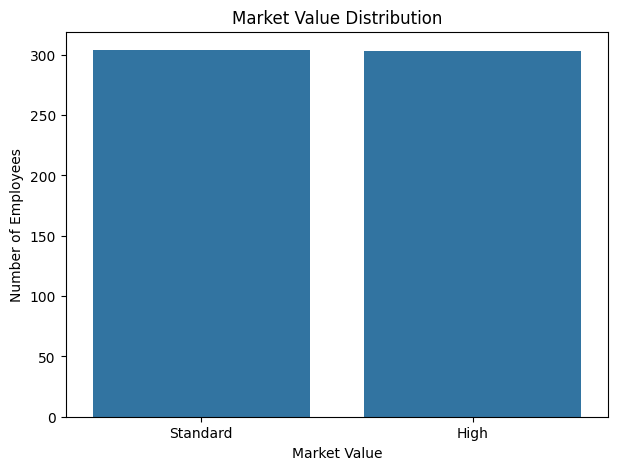

In [ ]:
# Graph 1: Market Value Distribution

plt.figure(figsize=(7, 5))

sns.countplot(
    x='market_value',
    data=df
)

plt.title('Market Value Distribution')
plt.xlabel('Market Value')
plt.ylabel('Number of Employees')

plt.show()

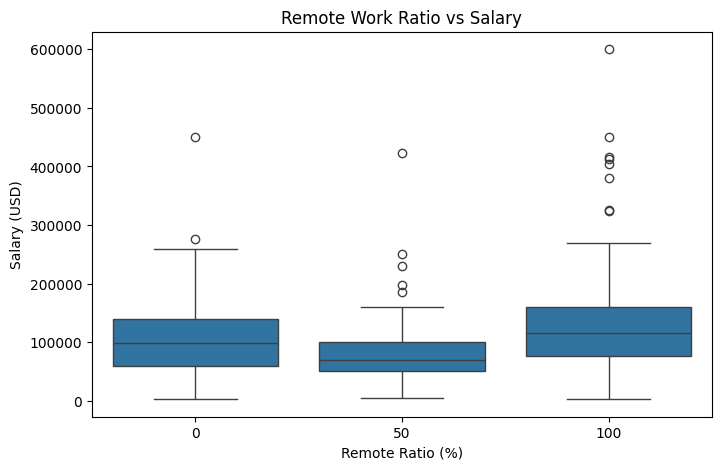

In [ ]:
# Graph 3: Remote Ratio vs Salary

plt.figure(figsize=(8, 5))

sns.boxplot(
    x='remote_ratio',
    y='salary_in_usd',
    data=df
)

plt.title('Remote Work Ratio vs Salary')
plt.xlabel('Remote Ratio (%)')
plt.ylabel('Salary (USD)')

plt.show()

##Step 5 — Logistic Regression

In [ ]:
# ============================================
# STEP 5: MACHINE LEARNING
# LOGISTIC REGRESSION
# ============================================

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Features
X = df[
    [
        'work_year',
        'experience_level',
        'employment_type',
        'job_title',
        'remote_ratio',
        'company_location',
        'company_size'
    ]
]

# Target
y = df['market_value']

# Categorical columns
categorical_columns = [
    'experience_level',
    'employment_type',
    'job_title',
    'company_location',
    'company_size'
]

# Encode categorical data
preprocessor = ColumnTransformer(
    transformers=[
        (
            'categorical',
            OneHotEncoder(handle_unknown='ignore'),
            categorical_columns
        )
    ],
    remainder='passthrough'
)

# Logistic Regression
model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('classifier', LogisticRegression(max_iter=1000))
    ]
)

# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Train model
model.fit(X_train, y_train)

print("Model training completed successfully.")
print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))

Model training completed successfully.
Training Records: 485
Testing Records: 122


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


##Step 6 — Accuracy

In [ ]:
# ============================================
# STEP 6: MODEL ACCURACY
# ============================================

from sklearn.metrics import accuracy_score

# Predict test data
y_pred = model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy)
print("Accuracy Percentage:", round(accuracy * 100, 2), "%")

Model Accuracy: 0.860655737704918
Accuracy Percentage: 86.07 %


##Step 7 — Confusion Matrix

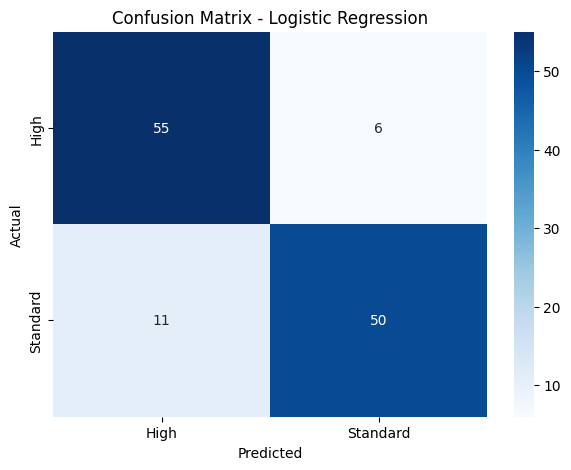

In [ ]:
# ============================================
# STEP 7: CONFUSION MATRIX
# ============================================

from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',-
    cmap='Blues',
    xticklabels=['High', 'Standard'],
    yticklabels=['High', 'Standard']
)

plt.title('Confusion Matrix - Logistic Regression')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.show()